In [1]:
#libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [2]:
#data load
data = pd.read_csv('D:\\O7-Machine-learning-test\\Data sets\\CVD_cleaned.csv')
data.head()

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,Poor,Within the past 2 years,No,No,No,No,No,No,Yes,Female,70-74,150.0,32.66,14.54,Yes,0.0,30.0,16.0,12.0
1,Very Good,Within the past year,No,Yes,No,No,No,Yes,No,Female,70-74,165.0,77.11,28.29,No,0.0,30.0,0.0,4.0
2,Very Good,Within the past year,Yes,No,No,No,No,Yes,No,Female,60-64,163.0,88.45,33.47,No,4.0,12.0,3.0,16.0
3,Poor,Within the past year,Yes,Yes,No,No,No,Yes,No,Male,75-79,180.0,93.44,28.73,No,0.0,30.0,30.0,8.0
4,Good,Within the past year,No,No,No,No,No,No,No,Male,80+,191.0,88.45,24.37,Yes,0.0,8.0,4.0,0.0


In [3]:
#info of dataset
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308854 entries, 0 to 308853
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   General_Health                308854 non-null  object 
 1   Checkup                       308854 non-null  object 
 2   Exercise                      308854 non-null  object 
 3   Heart_Disease                 308854 non-null  object 
 4   Skin_Cancer                   308854 non-null  object 
 5   Other_Cancer                  308854 non-null  object 
 6   Depression                    308854 non-null  object 
 7   Diabetes                      308854 non-null  object 
 8   Arthritis                     308854 non-null  object 
 9   Sex                           308854 non-null  object 
 10  Age_Category                  308854 non-null  object 
 11  Height_(cm)                   308854 non-null  float64
 12  Weight_(kg)                   308854 non-nul

In [4]:
#data description (mean , std, min, max, etc)
data.describe()


,Height_(cm),Weight_(kg),BMI,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
count,308854.000000,308854.000000,308854.000000,308854.000000,308854.000000,308854.000000,308854.000000
mean,170.615249,83.588655,28.626211,5.096366,29.835200,15.110441,6.296616
std,10.658026,21.343210,6.522323,8.199763,24.875735,14.926238,8.582954
min,91.000000,24.950000,12.020000,0.000000,0.000000,0.000000,0.000000
25%,163.000000,68.040000,24.210000,0.000000,12.000000,4.000000,2.000000
50%,170.000000,81.650000,27.440000,1.000000,30.000000,12.000000,4.000000
75%,178.000000,95.250000,31.850000,6.000000,30.000000,20.000000,8.000000
max,241.000000,293.020000,99.330000,30.000000,120.000000,128.000000,128.000000


In [5]:
#checking for null values
data.isnull().sum()

General_Health                  0
Checkup                         0
Exercise                        0
Heart_Disease                   0
Skin_Cancer                     0
Other_Cancer                    0
Depression                      0
Diabetes                        0
Arthritis                       0
Sex                             0
Age_Category                    0
Height_(cm)                     0
Weight_(kg)                     0
BMI                             0
Smoking_History                 0
Alcohol_Consumption             0
Fruit_Consumption               0
Green_Vegetables_Consumption    0
FriedPotato_Consumption         0
dtype: int64

In [6]:
# checking Duplicate records 
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", data.shape)

Duplicate rows: 80
Shape after dropping duplicates: (308774, 19)


Heart_Disease
No     283803
Yes     24971
Name: count, dtype: int64
Heart_Disease
No     0.919129
Yes    0.080871
Name: count, dtype: float64


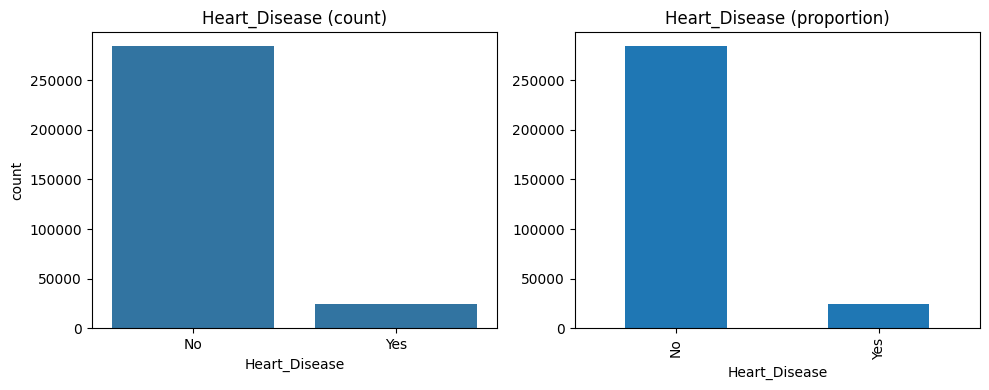

In [7]:
#Target class distribution
counts = data['Heart_Disease'].value_counts()
print(counts)
print(counts / len(data))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.countplot(x='Heart_Disease', data=data)
plt.title('Heart_Disease (count)')

plt.subplot(1, 2, 2)
counts.plot(kind='bar')
plt.title('Heart_Disease (proportion)')
plt.tight_layout()
plt.show()

In [8]:
# Preprocessing Feature / target split
X = data.drop(columns=['Heart_Disease'])
y = (data['Heart_Disease'] == 'Yes').astype(int)   # 1 = at risk of CVD, 0 = not at risk

numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Height_(cm)', 'Weight_(kg)', 'BMI', 'Alcohol_Consumption', 'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']
Categorical features: ['General_Health', 'Checkup', 'Exercise', 'Skin_Cancer', 'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Age_Category', 'Smoking_History']


In [9]:
# Train / test split (80% train, 20% test) 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class ratio:\n", y_train.value_counts(normalize=True).round(3))

Train: (247019, 18) | Test: (61755, 18)
Train class ratio:
 Heart_Disease
0    0.919
1    0.081
Name: proportion, dtype: float64


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Reusable preprocessing pipeline (fit on train data only -> no leakage).
# OneHotEncoder returns a dense matrix because HistGradientBoosting
# in Section 5 does not accept sparse input.
numeric_pipeline = Pipeline([('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features),
])

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


In [11]:
#Baselinemodel : Logistic Regression
baseline_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
])

baseline_model.fit(X_train, y_train)
print("Baseline model fitted.")

Baseline model fitted.


Accuracy : 0.9197
Precision: 0.5268
Recall   : 0.0629
F1-score : 0.1123

Classification report:
               precision    recall  f1-score   support

   No Disease       0.92      1.00      0.96     56761
Heart Disease       0.53      0.06      0.11      4994

     accuracy                           0.92     61755
    macro avg       0.73      0.53      0.54     61755
 weighted avg       0.89      0.92      0.89     61755



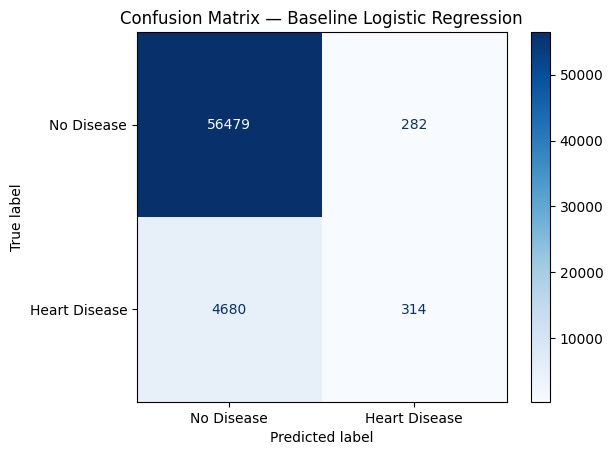

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = baseline_model.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['No Disease', 'Heart Disease']))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Disease', 'Heart Disease']).plot(cmap='Blues')
plt.title('Confusion Matrix — Baseline Logistic Regression')
plt.show()

In [13]:
import time
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score, precision_recall_curve

# Every trained model + its test predictions are registered here,
model_store = {}

def metrics_row(y_true, y_pred, y_score):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_score),
        'PR-AUC': average_precision_score(y_true, y_score),
    }

def add_to_store(name, model, y_score=None):
    if y_score is None:
        y_score = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    model_store[name] = {'model': model, 'y_pred': y_pred, 'y_score': y_score}
    row = metrics_row(y_test, y_pred, y_score)
    print(name, '->', {k: round(v, 4) for k, v in row.items()})
    return row

add_to_store('LogReg (baseline)', baseline_model);

LogReg (baseline) -> {'Accuracy': 0.9197, 'Precision': 0.5268, 'Recall': 0.0629, 'F1-score': 0.1123, 'ROC-AUC': 0.8386, 'PR-AUC': 0.3153}


In [14]:
from sklearn.svm import SVC

X_svm, _, y_svm, _ = train_test_split(
    X_train, y_train, train_size=30000, stratify=y_train, random_state=42
)
print('SVM training subsample:', X_svm.shape)

svm_variants = {
    'SVM | linear, C=1':            dict(kernel='linear', C=1),
    'SVM | rbf, C=1, gamma=scale':  dict(kernel='rbf', C=1, gamma='scale'),
    'SVM | rbf, C=10, gamma=scale': dict(kernel='rbf', C=10, gamma='scale'),
    'SVM | rbf, C=1, gamma=0.01':   dict(kernel='rbf', C=1, gamma=0.01),
}

svm_rows = []
for name, params in svm_variants.items():
    t0 = time.time()
    svm_pipe = Pipeline([
        ('preprocessing', preprocessor),
        ('model', SVC(random_state=42, **params)),
    ])
    svm_pipe.fit(X_svm, y_svm)
    y_score = svm_pipe.decision_function(X_test)
    y_pred = svm_pipe.predict(X_test)
    row = metrics_row(y_test, y_pred, y_score)
    svm_rows.append({'model': name, **{k: round(v, 4) for k, v in row.items()}, 'fit_sec': round(time.time() - t0)})
    model_store[name] = {'model': svm_pipe, 'y_pred': y_pred, 'y_score': y_score}
    print(f'{name} fitted in {time.time() - t0:.0f}s')

best_svm_name = max(svm_rows, key=lambda r: r['ROC-AUC'])['model']
print('Best SVM variant by ROC-AUC:', best_svm_name)
pd.DataFrame(svm_rows)

SVM training subsample: (30000, 18)


c:\Users\singh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


SVM | linear, C=1 fitted in 43s


c:\Users\singh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


SVM | rbf, C=1, gamma=scale fitted in 75s
SVM | rbf, C=10, gamma=scale fitted in 74s
SVM | rbf, C=1, gamma=0.01 fitted in 68s
Best SVM variant by ROC-AUC: SVM | rbf, C=10, gamma=scale


c:\Users\singh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,fit_sec
0,"SVM | linear, C=1",0.9191,0.0000,0.0000,0.0000,0.6514,0.1219,43
1,"SVM | rbf, C=1, gamma=scale",0.9191,0.0000,0.0000,0.0000,0.7048,0.1977,75
2,"SVM | rbf, C=10, gamma=scale",0.9180,0.4173,0.0348,0.0643,0.7068,0.1982,74
3,"SVM | rbf, C=1, gamma=0.01",0.9191,0.0000,0.0000,0.0000,0.6877,0.1857,68


               precision    recall  f1-score   support

   No Disease       0.92      1.00      0.96     56761
Heart Disease       0.42      0.03      0.06      4994

     accuracy                           0.92     61755
    macro avg       0.67      0.52      0.51     61755
 weighted avg       0.88      0.92      0.88     61755



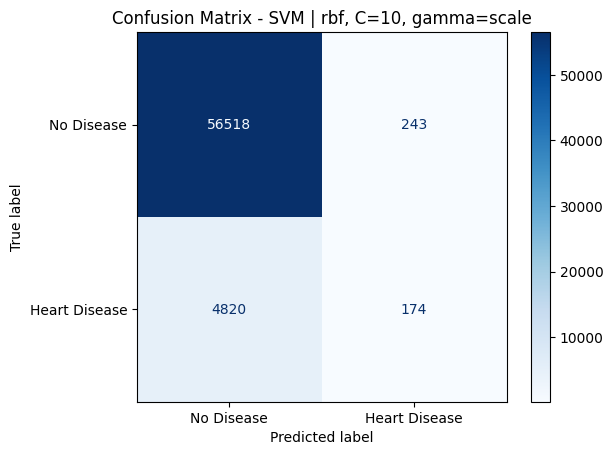

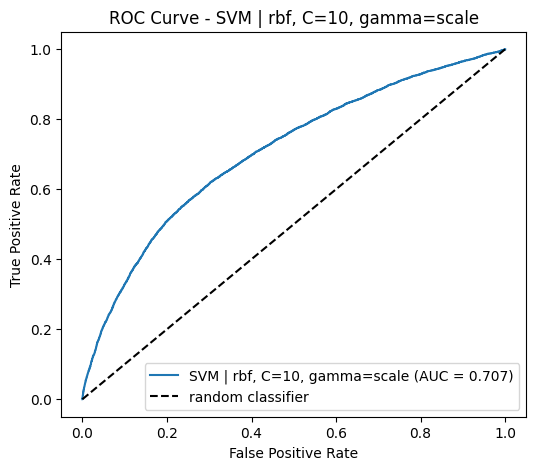

In [15]:
best_svm = model_store[best_svm_name]
y_pred, y_score = best_svm['y_pred'], best_svm['y_score']

print(classification_report(y_test, y_pred, target_names=['No Disease', 'Heart Disease']))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['No Disease', 'Heart Disease']).plot(cmap='Blues')
plt.title('Confusion Matrix - ' + best_svm_name)
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_score)
auc = roc_auc_score(y_test, y_score)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=best_svm_name + ' (AUC = ' + str(round(auc, 3)) + ')')
plt.plot([0, 1], [0, 1], 'k--', label='random classifier')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve - ' + best_svm_name)
plt.legend()
plt.show()

In [16]:
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

ensemble_models = {
    'Bagging | 50 trees': Pipeline([
        ('preprocessing', preprocessor),
        ('model', BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=14, random_state=42),
            n_estimators=50, n_jobs=-1, random_state=42)),
    ]),
    'RandomForest | 250 trees': Pipeline([
        ('preprocessing', preprocessor),
        ('model', RandomForestClassifier(n_estimators=250, n_jobs=-1, random_state=42)),
    ]),
    'HistGradientBoosting': Pipeline([
        ('preprocessing', preprocessor),
        ('model', HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=42)),
    ]),
    'AdaBoost': Pipeline([
        ('preprocessing', preprocessor),
        ('model', AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
            n_estimators=100, learning_rate=0.5, random_state=42)),
    ]),
}

In [17]:
ensemble_rows = []
for name, pipe in ensemble_models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    y_score = pipe.predict_proba(X_test)[:, 1]
    row = add_to_store(name, pipe, y_score=y_score)
    ensemble_rows.append({'model': name, **{k: round(v, 4) for k, v in row.items()}, 'fit_sec': round(time.time() - t0)})

pd.DataFrame(ensemble_rows)

Bagging | 50 trees -> {'Accuracy': 0.9182, 'Precision': 0.4561, 'Recall': 0.0573, 'F1-score': 0.1018, 'ROC-AUC': 0.829, 'PR-AUC': 0.2858}
RandomForest | 250 trees -> {'Accuracy': 0.9185, 'Precision': 0.4615, 'Recall': 0.0481, 'F1-score': 0.0871, 'ROC-AUC': 0.8141, 'PR-AUC': 0.2726}
HistGradientBoosting -> {'Accuracy': 0.9197, 'Precision': 0.5559, 'Recall': 0.0348, 'F1-score': 0.0656, 'ROC-AUC': 0.8402, 'PR-AUC': 0.3157}
AdaBoost -> {'Accuracy': 0.9192, 'Precision': 0.5125, 'Recall': 0.0082, 'F1-score': 0.0162, 'ROC-AUC': 0.8244, 'PR-AUC': 0.2884}


,model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,fit_sec
0,Bagging | 50 trees,0.9182,0.4561,0.0573,0.1018,0.8290,0.2858,18
1,RandomForest | 250 trees,0.9185,0.4615,0.0481,0.0871,0.8141,0.2726,10
2,HistGradientBoosting,0.9197,0.5559,0.0348,0.0656,0.8402,0.3157,5
3,AdaBoost,0.9192,0.5125,0.0082,0.0162,0.8244,0.2884,26


In [18]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=42
)
print('fit:', X_fit.shape, '| val:', X_val.shape, '| test:', X_test.shape)

rf_opt = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=250,
        class_weight='balanced_subsample',
        n_jobs=-1, random_state=42)),
])
t0 = time.time()
rf_opt.fit(X_fit, y_fit)
print('fitted %d trees in %.0fs' % (250, time.time() - t0))

val_score = rf_opt.predict_proba(X_val)[:, 1]

fit: (209966, 18) | val: (37053, 18) | test: (61755, 18)
fitted 250 trees in 10s


Best threshold by F1 on validation split: 0.16


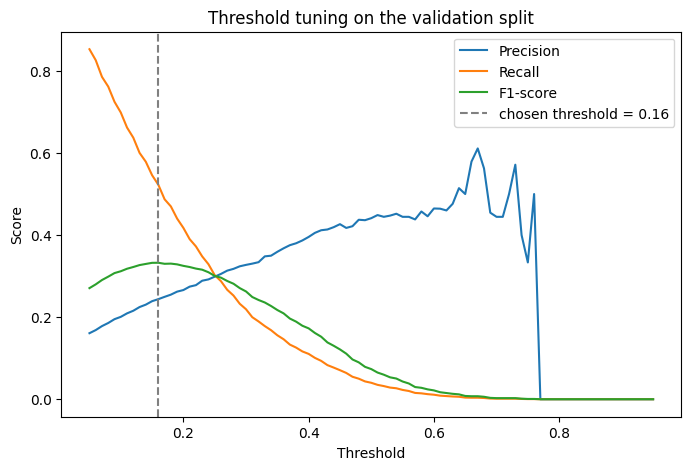

In [19]:
thresholds = np.linspace(0.05, 0.95, 91)
rows = []
for t in thresholds:
    y_pred_t = (val_score >= t).astype(int)
    rows.append({
        'threshold': t,
        'Precision': precision_score(y_val, y_pred_t, zero_division=0),
        'Recall': recall_score(y_val, y_pred_t, zero_division=0),
        'F1-score': f1_score(y_val, y_pred_t, zero_division=0),
    })
th_df = pd.DataFrame(rows)
best_t = float(th_df.loc[th_df['F1-score'].idxmax(), 'threshold'])
print('Best threshold by F1 on validation split:', round(best_t, 2))

plt.figure(figsize=(8, 5))
plt.plot(th_df['threshold'], th_df['Precision'], label='Precision')
plt.plot(th_df['threshold'], th_df['Recall'], label='Recall')
plt.plot(th_df['threshold'], th_df['F1-score'], label='F1-score')
plt.axvline(best_t, color='gray', linestyle='--', label='chosen threshold = ' + str(round(best_t, 2)))
plt.xlabel('Threshold'); plt.ylabel('Score')
plt.title('Threshold tuning on the validation split')
plt.legend()
plt.show()

In [20]:
test_score = rf_opt.predict_proba(X_test)[:, 1]
y_pred_opt = (test_score >= best_t).astype(int)

# register for Section 7
model_store['RF optimized (weights + tuned threshold)'] = {
    'model': rf_opt, 'y_pred': y_pred_opt, 'y_score': test_score}

before_after = []
for name, thr, y_pred, score in [
    ('BEFORE | LogReg baseline', 0.5,
     model_store['LogReg (baseline)']['y_pred'], model_store['LogReg (baseline)']['y_score']),
    ('BEFORE | RandomForest, thr=0.5', 0.5,
     model_store['RandomForest | 250 trees']['y_pred'], model_store['RandomForest | 250 trees']['y_score']),
    ('AFTER | RF weighted + tuned thr', best_t, y_pred_opt, test_score),
]:
    before_after.append({'model': name, 'threshold': round(thr, 2),
                         **{k: round(v, 4) for k, v in metrics_row(y_test, y_pred, score).items()}})

pd.DataFrame(before_after)

,model,threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,BEFORE | LogReg baseline,0.50,0.9197,0.5268,0.0629,0.1123,0.8386,0.3153
1,"BEFORE | RandomForest, thr=0.5",0.50,0.9185,0.4615,0.0481,0.0871,0.8141,0.2726
2,AFTER | RF weighted + tuned thr,0.16,0.8365,0.2568,0.5398,0.3481,0.8155,0.2703


In [21]:
summary_rows = []
for name, entry in model_store.items():
    summary_rows.append({'model': name,
                         **{k: round(v, 4) for k, v in metrics_row(y_test, entry['y_pred'], entry['y_score']).items()}})

df_summary = pd.DataFrame(summary_rows).sort_values('F1-score', ascending=False).reset_index(drop=True)
df_summary

c:\Users\singh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\singh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\singh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

,model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,RF optimized (weights + tuned threshold),0.8365,0.2568,0.5398,0.3481,0.8155,0.2703
1,LogReg (baseline),0.9197,0.5268,0.0629,0.1123,0.8386,0.3153
2,Bagging | 50 trees,0.9182,0.4561,0.0573,0.1018,0.8290,0.2858
3,RandomForest | 250 trees,0.9185,0.4615,0.0481,0.0871,0.8141,0.2726
4,HistGradientBoosting,0.9197,0.5559,0.0348,0.0656,0.8402,0.3157
5,"SVM | rbf, C=10, gamma=scale",0.9180,0.4173,0.0348,0.0643,0.7068,0.1982
6,AdaBoost,0.9192,0.5125,0.0082,0.0162,0.8244,0.2884
7,"SVM | linear, C=1",0.9191,0.0000,0.0000,0.0000,0.6514,0.1219
8,"SVM | rbf, C=1, gamma=0.01",0.9191,0.0000,0.0000,0.0000,0.6877,0.1857
9,"SVM | rbf, C=1, gamma=scale",0.9191,0.0000,0.0000,0.0000,0.7048,0.1977


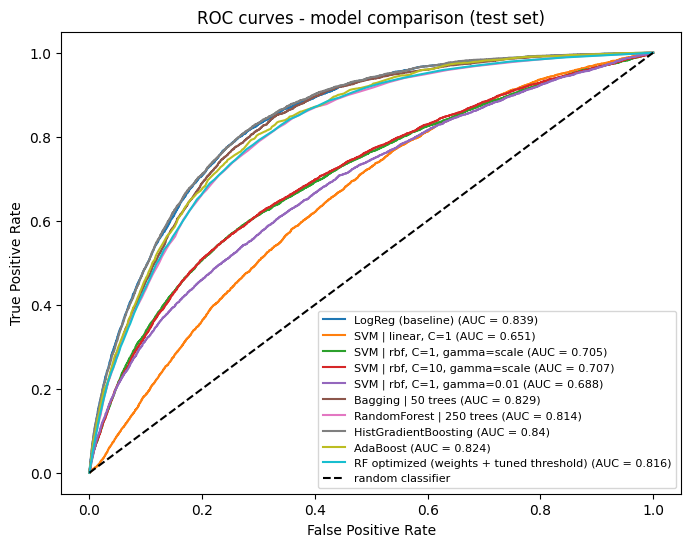

In [22]:
plt.figure(figsize=(8, 6))
for name, entry in model_store.items():
    fpr, tpr, _ = roc_curve(y_test, entry['y_score'])
    auc = roc_auc_score(y_test, entry['y_score'])
    plt.plot(fpr, tpr, label=name + ' (AUC = ' + str(round(auc, 3)) + ')')
plt.plot([0, 1], [0, 1], 'k--', label='random classifier')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC curves - model comparison (test set)')
plt.legend(loc='lower right', fontsize=8)
plt.show()

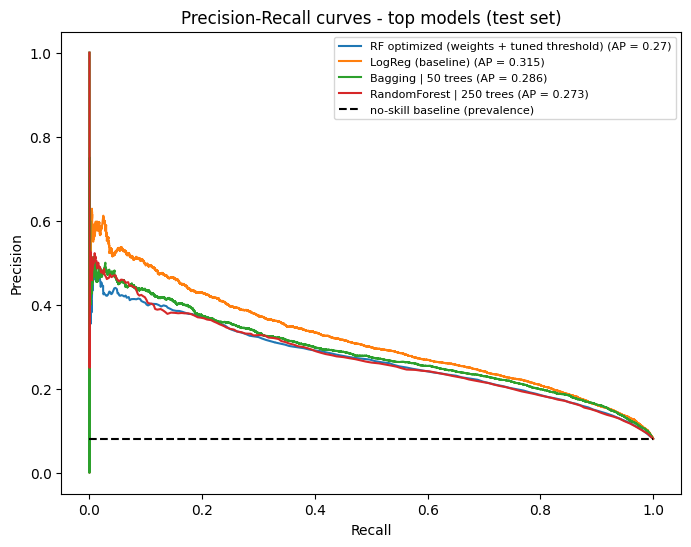

In [23]:
top_names = df_summary.head(4)['model'].tolist()

plt.figure(figsize=(8, 6))
for name in top_names:
    y_score = model_store[name]['y_score']
    prec, rec, _ = precision_recall_curve(y_test, y_score)
    ap = average_precision_score(y_test, y_score)
    plt.plot(rec, prec, label=name + ' (AP = ' + str(round(ap, 3)) + ')')
plt.hlines(y_test.mean(), 0, 1, colors='k', linestyles='--', label='no-skill baseline (prevalence)')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall curves - top models (test set)')
plt.legend(loc='upper right', fontsize=8)
plt.show()

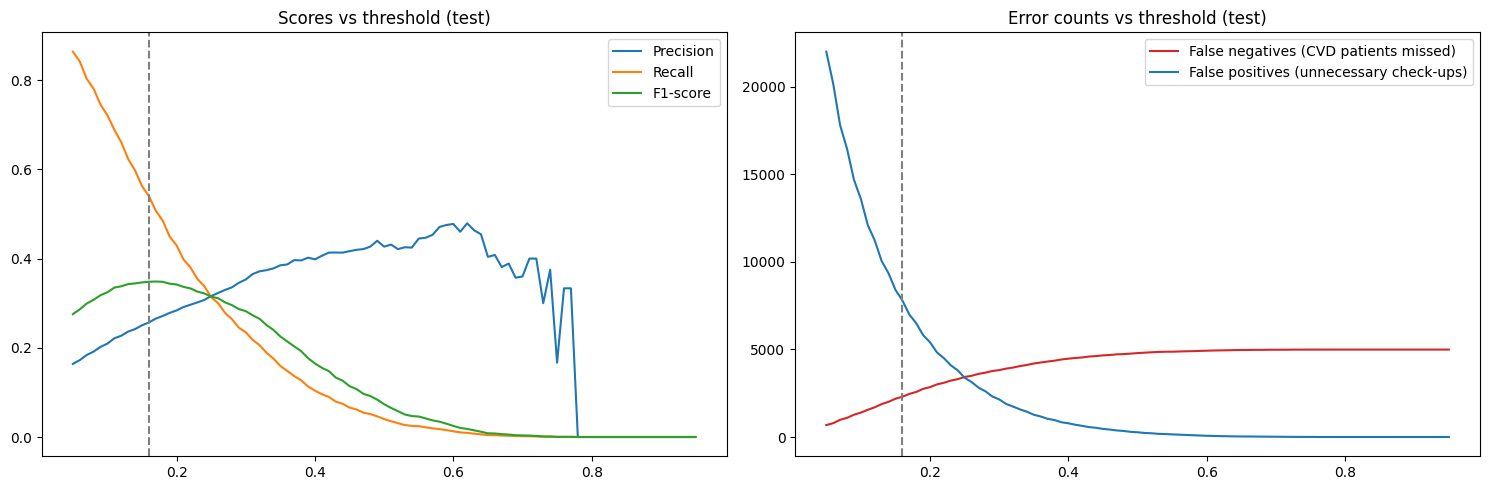

               precision    recall  f1-score   support

   No Disease       0.96      0.86      0.91     56761
Heart Disease       0.26      0.54      0.35      4994

     accuracy                           0.84     61755
    macro avg       0.61      0.70      0.63     61755
 weighted avg       0.90      0.84      0.86     61755



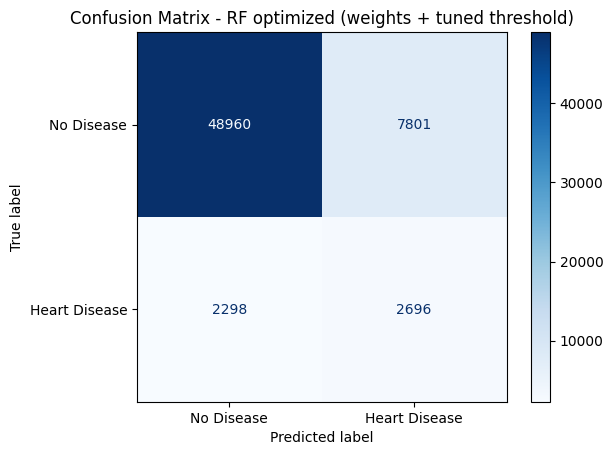

In [24]:
opt_name = 'RF optimized (weights + tuned threshold)'
test_score = model_store[opt_name]['y_score']

sweep = []
for t in np.linspace(0.05, 0.95, 91):
    y_pred_t = (test_score >= t).astype(int)
    sweep.append({
        'threshold': t,
        'FalsePos': int(((y_pred_t == 1) & (y_test == 0)).sum()),
        'FalseNeg': int(((y_pred_t == 0) & (y_test == 1)).sum()),
        'Precision': precision_score(y_test, y_pred_t, zero_division=0),
        'Recall': recall_score(y_test, y_pred_t, zero_division=0),
        'F1-score': f1_score(y_test, y_pred_t, zero_division=0),
    })
sw_df = pd.DataFrame(sweep)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(sw_df['threshold'], sw_df['Precision'], label='Precision')
axes[0].plot(sw_df['threshold'], sw_df['Recall'], label='Recall')
axes[0].plot(sw_df['threshold'], sw_df['F1-score'], label='F1-score')
axes[0].axvline(best_t, color='gray', linestyle='--')
axes[0].set_title('Scores vs threshold (test)')
axes[0].legend()

axes[1].plot(sw_df['threshold'], sw_df['FalseNeg'], color='tab:red', label='False negatives (CVD patients missed)')
axes[1].plot(sw_df['threshold'], sw_df['FalsePos'], color='tab:blue', label='False positives (unnecessary check-ups)')
axes[1].axvline(best_t, color='gray', linestyle='--')
axes[1].set_title('Error counts vs threshold (test)')
axes[1].legend()

plt.tight_layout()
plt.show()

print(classification_report(y_test, model_store[opt_name]['y_pred'],
                            target_names=['No Disease', 'Heart Disease']))
ConfusionMatrixDisplay(confusion_matrix(y_test, model_store[opt_name]['y_pred']),
                       display_labels=['No Disease', 'Heart Disease']).plot(cmap='Blues')
plt.title('Confusion Matrix - ' + opt_name)
plt.show()